In [9]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import os
os.chdir('/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO')
print(os.getcwd())


/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO


In [11]:
import os
import copy
import random
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.models import ResNet50_Weights

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Select Runtime > Change runtime type > GPU.")

PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [15]:
########################################
# EFINE DATASET AND MODEL OUTPUT PATHS
########################################

DATA_DIR = "/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO/dataset"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "val")
TEST_DIR = os.path.join(DATA_DIR, "test")

# The trained checkpoint will be saved here.
OUTPUT_DIR = "/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO/malaria_model_output"

os.makedirs(OUTPUT_DIR, exist_ok=True)

CHECKPOINT_PATH = os.path.join(
    OUTPUT_DIR, "LR_model.pth"
)

for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    if not os.path.isdir(folder):
        raise FileNotFoundError(
            f"Folder not found: {folder}\n"
            "Please update DATA_DIR in Cell 3."
        )

print("Dataset directory:", DATA_DIR)
print("Training directory:", TRAIN_DIR)
print("Validation directory:", VAL_DIR)
print("Test directory:", TEST_DIR)
print("Model output path:", CHECKPOINT_PATH)

Dataset directory: /content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO/dataset
Training directory: /content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO/dataset/train
Validation directory: /content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO/dataset/val
Test directory: /content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO/dataset/test
Model output path: /content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO/malaria_model_output/LR_model.pth


In [18]:
#####################################################
# IMAGE PREPROCESSING AND DATASET LOADING
#####################################################

# the standard input size for ResNet-50's ImageNet pretrained weights.
IMAGE_SIZE = 224

# Process 32 images together in each training batch.
BATCH_SIZE = 32

# Number of worker processes used to load images.
NUM_WORKERS = 2

# Normalization values
MEAN = [0.4326, 0.4953, 0.3120]
STD = [0.2178, 0.2214, 0.2091]

#####################################################
# Training transformations
#####################################################
# Resize: gives every image the same dimensions.
# RandomHorizontalFlip: helps the model learn from mirrored cells.
# RandomRotation: introduces small orientation variations.
# ToTensor: converts images into PyTorch tensors.
# Normalize: scales channel values using the selected mean/std.
#
# Augmentation is applied only to training images.

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

######################################################
# Validation and test transformations
#####################################################
# These images are resized and normalized without random
# augmentation, allowing consistent evaluation.

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# ImageFolder automatically reads class labels from subfolders.
train_ds = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_ds = datasets.ImageFolder(
    VAL_DIR,
    transform=eval_transform
)

test_ds = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)

# Print the mapping between class names and numeric labels.
print("Class mapping:", train_ds.class_to_idx)
print("Class names:", train_ds.classes)

# Gradio prediction code expects:
# Parasitized = 0
# Uninfected = 1
expected_mapping = {
    "parasitized": 0,
    "uninfected": 1
}

# Stop if the training folders produce a different label mapping.
if train_ds.class_to_idx != expected_mapping:
    raise ValueError(
        f"Unexpected class mapping: {train_ds.class_to_idx}. "
        f"Expected {expected_mapping}."
    )

# Ensure validation and test datasets use the same label mapping.
if val_ds.class_to_idx != train_ds.class_to_idx:
    raise ValueError("Validation class mapping differs from training.")

if test_ds.class_to_idx != train_ds.class_to_idx:
    raise ValueError("Test class mapping differs from training.")

# Display total images and class counts for each split.
def print_class_counts(dataset, name):
    counts = {class_name: 0 for class_name in dataset.classes}

    for _, label in dataset.samples:
        counts[dataset.classes[label]] += 1

    print(f"{name}: {len(dataset)} images")
    print("Class distribution:", counts)

print_class_counts(train_ds, "Training")
print_class_counts(val_ds, "Validation")
print_class_counts(test_ds, "Test")

# Warn if the actual image counts differ from your planned split.
if len(train_ds) != 1000:
    print("Warning: expected 1000 training images.")

if len(val_ds) != 200:
    print("Warning: expected 200 validation images.")

if len(test_ds) != 200:
    print("Warning: expected 200 test images.")

Class mapping: {'parasitized': 0, 'uninfected': 1}
Class names: ['parasitized', 'uninfected']
Training: 1000 images
Class distribution: {'parasitized': 500, 'uninfected': 500}
Validation: 200 images
Class distribution: {'parasitized': 100, 'uninfected': 100}
Test: 200 images
Class distribution: {'parasitized': 100, 'uninfected': 100}


In [19]:
######################################################
# CREATE DATALOADERS
######################################################


# Training data is shuffled so the model does not see the
# training examples in the same order every epoch.
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# Display how many batches will be processed in each split.
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 32
Validation batches: 7
Test batches: 7


In [20]:
######################################################
# LOAD THE PRETRAINED RESNET-50 MODEL
######################################################

# Load ResNet-50 with ImageNet pretrained weights.
model = models.resnet50(
    weights=ResNet50_Weights.DEFAULT
)

# ResNet-50's original fully connected layer produces 1000
# ImageNet class scores. Replace it with a malaria classifier.
# Linear: maps extracted features to 256 values.
# Final Linear: outputs two scores, one for each class.
model.fc = nn.Sequential(
    nn.Linear(model.fc.in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 2)
)

# Move the model to the GPU when available.
model = model.to(device)

# CrossEntropyLoss for two-class classification
criterion = nn.CrossEntropyLoss()

# Freeze all pretrained layers initially.
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the newly added classification head.
for param in model.fc.parameters():
    param.requires_grad = True

print("ResNet-50 is ready.")
print("Output classes:", model.fc[-1].out_features)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 113MB/s]


ResNet-50 is ready.
Output classes: 2
Device: cuda


In [21]:
######################################################
# TRAINING AND VALIDATION FUNCTION
######################################################

def run_one_epoch(model, loader, criterion, optimizer=None):
    """
    Run one complete pass through a dataset.

    If an optimizer is supplied:
        - Enable training mode.
        - Calculate loss.
        - Backpropagate gradients.
        - Update model parameters.

    If no optimizer is supplied:
        - Use evaluation mode.
        - Calculate loss and predictions only.
        - Do not update model parameters.

    Returns:
        Average loss, accuracy and F1-score for Parasitized.
    """

    # Training pass.
    training = optimizer is not None


    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    # Process each batch of images and labels.
    for images, labels in loader:

        # Transfer tensors to the selected device.
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear gradients from the previous training batch.
        if training:
            optimizer.zero_grad(set_to_none=True)

        # Enable gradients only when training.
        with torch.set_grad_enabled(training):

            # Forward pass: generate two class scores per image.
            outputs = model(images)

            # Compare predictions with the true labels.
            loss = criterion(outputs, labels)

            # Backward pass and parameter update.
            if training:
                loss.backward()
                optimizer.step()

        # Accumulate loss weighted by the batch size.
        total_loss += loss.item() * images.size(0)

        # Choose the class with the largest output score.
        predictions = outputs.argmax(dim=1)

        # Collect predictions and true labels for metrics.
        all_labels.extend(labels.detach().cpu().numpy())
        all_predictions.extend(predictions.detach().cpu().numpy())

    # Calculate average loss across all images.
    epoch_loss = total_loss / len(loader.dataset)

    # Accuracy is the proportion of correctly classified images.
    epoch_accuracy = accuracy_score(
        all_labels, all_predictions
    )

    # Calculate F1 for Parasitized (class index 0).
    # zero_division=0 avoids errors if no samples are predicted
    # as positive for this class.
    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        pos_label=0,
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


# Store the measurements from every epoch for later plotting.
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_f1": [],
    "val_f1": []
}

# Track the best validation F1-score observed so far.
best_val_f1 = -1.0

# Record which epoch produced the best checkpoint.
best_epoch = 0

In [22]:
######################################################
# CHECKPOINT SAVING FUNCTION
######################################################

def save_checkpoint(epoch, val_f1):
    """
    Save the current model when it achieves a new best
    validation F1-score.

    Saving the state_dict allows the model to be reconstructed
    later in the Gradio app without saving the entire model object.
    """

    checkpoint = {
        # Learned parameters of the complete ResNet-50.
        "model_state_dict": copy.deepcopy(model.state_dict()),

        # Record which numeric label corresponds to each class.
        "class_to_idx": train_ds.class_to_idx,

        # Store preprocessing settings for consistent inference.
        "mean": MEAN,
        "std": STD,
        "image_size": IMAGE_SIZE,

        # Store evaluation metadata.
        "epoch": epoch,
        "val_f1": val_f1,
        "architecture": "resnet50"
    }

    # Write the checkpoint to Google Drive.
    torch.save(checkpoint, CHECKPOINT_PATH)

    print("Best checkpoint saved to:", CHECKPOINT_PATH)

In [23]:
######################################################
# PHASE 1 - TRAIN THE CLASSIFICATION HEAD
######################################################

# Number of epochs for the first training phase.
HEAD_EPOCHS = 4

# Only the classification head is trainable in this phase.
head_optimizer = AdamW(
    (p for p in model.parameters() if p.requires_grad),
    lr=1e-3,
    weight_decay=1e-4
)

# Reduce the learning rate if validation F1 stops improving.
head_scheduler = ReduceLROnPlateau(
    head_optimizer,
    mode="max",
    factor=0.5,
    patience=1
)

for epoch in range(1, HEAD_EPOCHS + 1):

    start_time = time.time()

    # Train the classification head using training images.
    train_loss, train_acc, train_f1 = run_one_epoch(
        model,
        train_loader,
        criterion,
        head_optimizer
    )

    # Evaluate on validation images without updating parameters.
    val_loss, val_acc, val_f1 = run_one_epoch(
        model,
        val_loader,
        criterion
    )

    # Save the results so we can plot the learning curves later.
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    # Adjust the learning rate based on validation F1.
    head_scheduler.step(val_f1)

    elapsed = time.time() - start_time

    # Display the progress for this epoch.
    print(
        f"Epoch {epoch}/{HEAD_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_acc:.4f} | "
        f"Validation loss: {val_loss:.4f} | "
        f"Validation accuracy: {val_acc:.4f} | "
        f"Validation F1: {val_f1:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

    # Saves the model only when validation F1 improves.
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = len(history["val_f1"])

        save_checkpoint(best_epoch, best_val_f1)

print("Classification-head training complete.")

Epoch 1/4 | Train loss: 0.3022 | Train accuracy: 0.8820 | Validation loss: 0.1844 | Validation accuracy: 0.9400 | Validation F1: 0.9394 | Time: 252.8s
Best checkpoint saved to: /content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO/malaria_model_output/LR_model.pth
Epoch 2/4 | Train loss: 0.1426 | Train accuracy: 0.9510 | Validation loss: 0.1588 | Validation accuracy: 0.9400 | Validation F1: 0.9388 | Time: 8.0s
Epoch 3/4 | Train loss: 0.1115 | Train accuracy: 0.9660 | Validation loss: 0.1721 | Validation accuracy: 0.9400 | Validation F1: 0.9412 | Time: 6.3s
Best checkpoint saved to: /content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO/malaria_model_output/LR_model.pth
Epoch 4/4 | Train loss: 0.0987 | Train accuracy: 0.9670 | Validation loss: 0.2017 | Validation accuracy: 0.9250 | Validation F1: 0.9289 | Time: 7.7s
Classification-head training complete.


In [24]:
######################################################
# PHASE 2 - FINE-TUNE RESNET-50
######################################################

# Freeze every parameter before selectively unfreezing layers.
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the final residual block.
# Earlier layers retain more of their pretrained features.
for param in model.layer4.parameters():
    param.requires_grad = True

# Keep the classification head trainable as well.
for param in model.fc.parameters():
    param.requires_grad = True

# Set the maximum number of fine-tuning epochs.
FINE_TUNE_EPOCHS = 10

# Low learning rate for pretrained features and a higher
# learning rate for the new classification head.
optimizer = AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.fc.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

# Reduce learning rates if validation F1 stops improving.
scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

# Stop early if validation F1 fails to improve for four epochs.
patience = 4
epochs_without_improvement = 0

for epoch in range(1, FINE_TUNE_EPOCHS + 1):

    start_time = time.time()

    # Update layer4 and the classification head.
    train_loss, train_acc, train_f1 = run_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    # Measure generalization on the validation set.
    val_loss, val_acc, val_f1 = run_one_epoch(
        model,
        val_loader,
        criterion
    )

    # Record metrics for plots and analysis.
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    scheduler.step(val_f1)

    elapsed = time.time() - start_time

    print(
        f"Fine-tune epoch {epoch}/{FINE_TUNE_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_acc:.4f} | "
        f"Validation loss: {val_loss:.4f} | "
        f"Validation accuracy: {val_acc:.4f} | "
        f"Validation F1: {val_f1:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

    # If validation F1 improves, save the new best model.
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = len(history["val_f1"])

        save_checkpoint(best_epoch, best_val_f1)

        # Reset early-stopping counter after an improvement.
        epochs_without_improvement = 0

    else:
        # Count consecutive epochs without improvement.
        epochs_without_improvement += 1

    # Stop training if validation performance has stopped improving.
    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

print("Fine-tuning complete.")
print("Best validation F1:", round(best_val_f1, 4))
print("Best epoch:", best_epoch)
print("Saved checkpoint:", CHECKPOINT_PATH)

Fine-tune epoch 1/10 | Train loss: 0.0871 | Train accuracy: 0.9720 | Validation loss: 0.1825 | Validation accuracy: 0.9300 | Validation F1: 0.9333 | Time: 8.2s
Fine-tune epoch 2/10 | Train loss: 0.0766 | Train accuracy: 0.9700 | Validation loss: 0.1598 | Validation accuracy: 0.9450 | Validation F1: 0.9458 | Time: 6.4s
Best checkpoint saved to: /content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO/malaria_model_output/LR_model.pth
Fine-tune epoch 3/10 | Train loss: 0.0823 | Train accuracy: 0.9700 | Validation loss: 0.1858 | Validation accuracy: 0.9300 | Validation F1: 0.9327 | Time: 8.0s
Fine-tune epoch 4/10 | Train loss: 0.0548 | Train accuracy: 0.9870 | Validation loss: 0.1888 | Validation accuracy: 0.9350 | Validation F1: 0.9378 | Time: 8.2s
Fine-tune epoch 5/10 | Train loss: 0.0522 | Train accuracy: 0.9840 | Validation loss: 0.1658 | Validation accuracy: 0.9400 | Validation F1: 0.9417 | Time: 8.3s
Fine-tune epoch 6/10 | Train loss: 0.0527 |

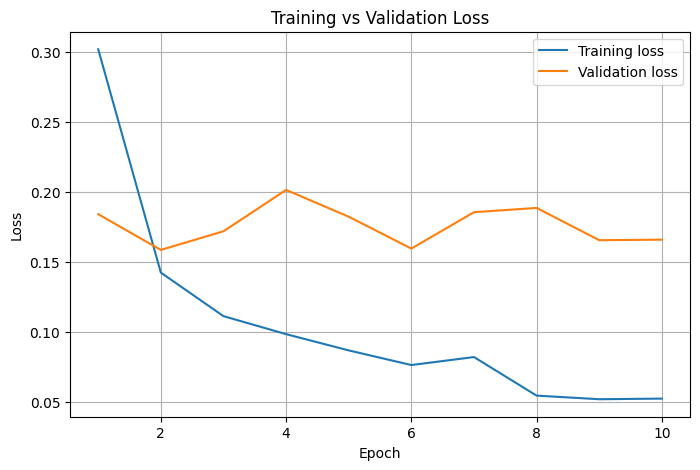

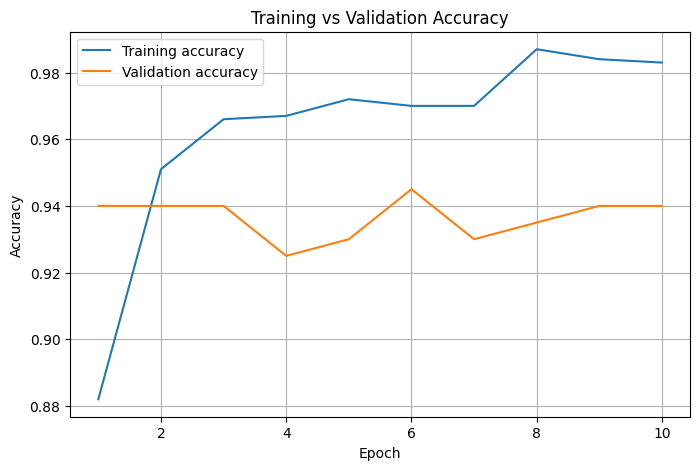

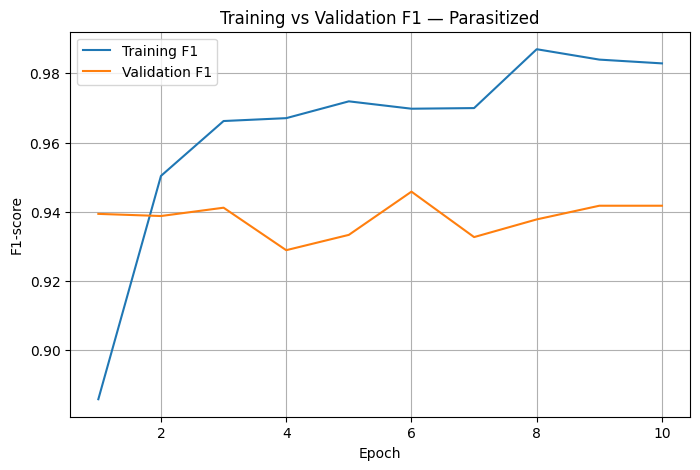

In [25]:
######################################################
# VISUALIZE TRAINING PROGRESS
######################################################

# Epoch numbers are used as the horizontal axis.
epochs = range(1, len(history["train_loss"]) + 1)


# Plot 1: Training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_loss"], label="Training loss")
plt.plot(epochs, history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()



# Plot 2: Training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_acc"], label="Training accuracy")
plt.plot(epochs, history["val_acc"], label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()



# Plot 3: Training and validation F1-score
# F1 combines precision and recall for the Parasitized class.
plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_f1"], label="Training F1")
plt.plot(epochs, history["val_f1"], label="Validation F1")

plt.xlabel("Epoch")
plt.ylabel("F1-score")
plt.title("Training vs Validation F1 — Parasitized")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
######################################################
# FINAL TEST SET EVALUATION
######################################################

# Reload the best model selected using validation F1.
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

# Lists will store all test labels and predictions.
y_true = []
y_pred = []

# Disable gradient calculation because we are only evaluating.
with torch.inference_mode():

    for images, labels in test_loader:

        # Move test images to the selected device.
        images = images.to(device, non_blocking=True)

        # Generate the model's two class scores per image.
        outputs = model(images)

        # Convert each output into the predicted class index.
        predictions = outputs.argmax(dim=1)

        # Keep labels and predictions on the CPU for sklearn.
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())


######################################################
# final test metrics.
######################################################

# Accuracy
test_accuracy = accuracy_score(y_true, y_pred)

# Precision for Parasitized
test_precision = precision_score(
    y_true,
    y_pred,
    pos_label=0,
    zero_division=0
)

# Recall for Parasitized:
test_recall = recall_score(
    y_true,
    y_pred,
    pos_label=0,
    zero_division=0
)

# F1-score balances precision and recall.
test_f1 = f1_score(
    y_true,
    y_pred,
    pos_label=0,
    zero_division=0
)

print("Best checkpoint epoch:", checkpoint["epoch"])
print()
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test precision (Parasitized): {test_precision:.4f}")
print(f"Test recall (Parasitized): {test_recall:.4f}")
print(f"Test F1-score (Parasitized): {test_f1:.4f}")

# Display precision, recall, F1 and sample counts for both classes.
print("\nDetailed classification report:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Parasitized", "Uninfected"],
        digits=4,
        zero_division=0
    )
)

Best checkpoint epoch: 6

Test accuracy: 0.9700
Test precision (Parasitized): 0.9700
Test recall (Parasitized): 0.9700
Test F1-score (Parasitized): 0.9700

Detailed classification report:
              precision    recall  f1-score   support

 Parasitized     0.9700    0.9700    0.9700       100
  Uninfected     0.9700    0.9700    0.9700       100

    accuracy                         0.9700       200
   macro avg     0.9700    0.9700    0.9700       200
weighted avg     0.9700    0.9700    0.9700       200



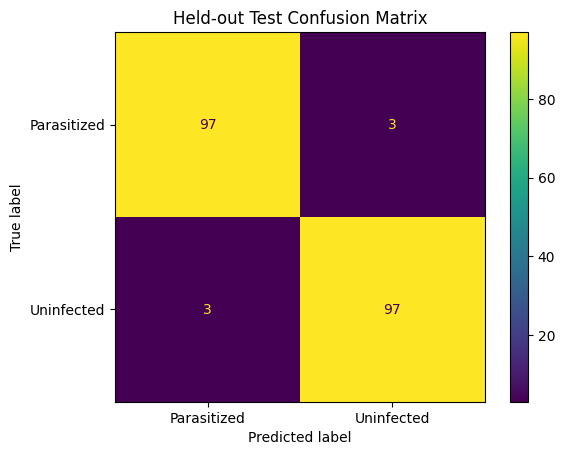

Confusion matrix:
[[97  3]
 [ 3 97]]


In [28]:
######################################################
# CONFUSION MATRIX
######################################################


# index 0 = Parasitized
# index 1 = Uninfected
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Parasitized", "Uninfected"]
)

disp.plot(values_format="d")

plt.title("Held-out Test Confusion Matrix")
plt.show()


print("Confusion matrix:")
print(cm)


In [29]:
######################################################
# EXPORT THE BEST MODEL CHECKPOINT
######################################################

# Google Drive retains the checkpoint at this location:
print("Saved checkpoint:", CHECKPOINT_PATH)

# Download model
from google.colab import files

files.download(CHECKPOINT_PATH)

Saved checkpoint: /content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac7-CHIPOMPO/malaria_model_output/LR_model.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
######################################################
# VERIFY CHECKPOINT CONTENTS
######################################################

# Check that the model file exists before deploying it.
assert os.path.exists(CHECKPOINT_PATH), "Checkpoint file not found."

# Load the saved metadata for inspection.
saved_checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu"
)

print("File exists:", os.path.exists(CHECKPOINT_PATH))

# Display file size in megabytes.
size_mb = os.path.getsize(CHECKPOINT_PATH) / (1024 * 1024)
print(f"File size: {size_mb:.2f} MB")

# Verify the architecture, label mapping and preprocessing settings.
print("Architecture:", saved_checkpoint["architecture"])
print("Best epoch:", saved_checkpoint["epoch"])
print("Best validation F1:", saved_checkpoint["val_f1"])
print("Class mapping:", saved_checkpoint["class_to_idx"])
print("Image size:", saved_checkpoint["image_size"])
print("Mean:", saved_checkpoint["mean"])
print("Standard deviation:", saved_checkpoint["std"])

File exists: True
File size: 91.98 MB
Architecture: resnet50
Best epoch: 6
Best validation F1: 0.9458128078817734
Class mapping: {'parasitized': 0, 'uninfected': 1}
Image size: 224
Mean: [0.4326, 0.4953, 0.312]
Standard deviation: [0.2178, 0.2214, 0.2091]


In [ ]:
######################################################
# GRADIO INFERENCE CODE
######################################################

import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image

# Path to the checkpoint downloaded from Colab.
# Keep LR_model.pth beside app.py, or change this path.
CHECKPOINT_PATH = "LR_model.pth"

# Load checkpoint on CPU, which is suitable for a basic
# Gradio app running without a dedicated GPU.
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu"
)

# Recreate exactly the same ResNet-50 architecture used in training.
# weights=None prevents downloading ImageNet weights because
# the learned model parameters are loaded from our checkpoint.
model = models.resnet50(weights=None)

# Recreate the same two-class output head.
model.fc = nn.Sequential(
    nn.Linear(model.fc.in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 2)
)

# Restore the fine-tuned parameters.
model.load_state_dict(checkpoint["model_state_dict"])

# Put the model in evaluation mode to disable dropout.
model.eval()

# Keep this order consistent with the training class mapping.
class_names = ["Parasitized", "Uninfected"]

# Apply the same resizing and normalization used in training.
# The values are read from the saved checkpoint to help keep
# inference preprocessing consistent with training.
transform = transforms.Compose([
    transforms.Resize((checkpoint["image_size"], checkpoint["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(
        checkpoint["mean"],
        checkpoint["std"]
    )
])


def predict(img):
    """
    Predict the model's class probabilities for one cell image.

    img: PIL image supplied by Gradio.

    Returns a dictionary mapping class names to probabilities.
    These scores describe model output, not clinical certainty.
    """

    # Ensure the input has three color channels.
    img = img.convert("RGB")

    # Apply preprocessing and add a batch dimension.
    # Shape becomes [1, 3, 224, 224].
    tensor = transform(img).unsqueeze(0)

    # Prediction does not require gradients.
    with torch.inference_mode():

        # Get the two raw class scores.
        outputs = model(tensor)

        # Convert scores to probabilities that sum to 1.
        probabilities = torch.softmax(outputs, dim=1)[0]

    # Gradio's Label output can display these class scores.
    return {
        class_names[i]: float(probabilities[i])
        for i in range(len(class_names))
    }

In [ ]:
import gradio as gr

interface = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=2),
    title="Malaria Cell Classification",
    description=(
        "Educational classification of blood-smear cell images. "
        "This model is not a medical diagnostic tool."
    )
)

interface.launch()

[Huggingface link](https://huggingface.co/spaces/kbesa/Malaria-Cell-Classifier)